# 07 · Phân tích mở rộng

Ba phân tích bổ sung, đều chỉ dựa trên train/OOF; test chỉ xuất hiện trong hình độ tin cậy để kiểm tra.

1. **Độ tin cậy của xác suất và hiệu chỉnh.** Điểm rủi ro của mô hình có đọc được như xác suất thật không? Đây là điều kiện để (a) nhân xác suất với quy mô thiệt hại trong chính sách "thiệt hại kỳ vọng" ở `05_cost`, và (b) in con số xác suất lên phiếu cảnh báo cho quản đốc.
2. **Learning curve theo thời gian.** Có thêm dữ liệu thì mô hình có tốt hơn không? Trả lời câu hỏi "giới hạn nằm ở lượng dữ liệu hay ở thông tin trong đặc trưng".
3. **Phiếu cảnh báo đầu ca.** Biến kết quả thành công cụ dùng được mỗi sáng.

Việc so sánh và chọn giữa các chính sách xếp hạng (theo điểm rủi ro, theo thiệt hại kỳ vọng, có hoặc không hiệu chỉnh) đã được làm ở `05_cost`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # chạy được từ notebooks/ hoặc từ gốc repo
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)

from config import DATA_FILE, SEED
import plots as P

import features as F
import splits as S
import evaluate as E
import pipeline as PL
import cost as C
import calibration as CAL
import learning_curve as LC
import alert_sheet as AS

df = F.build_dataset(DATA_FILE)
train, test = S.split_train_test(df)
cv = S.RollingOriginByDate(n_blocks=6)
sel = E.select_models(train, "A", cv)        # khoảng 40 giây
summ = E.summarize_folds(sel["folds"])
main = summ.sort_values("average_precision_mean", ascending=False).model.iloc[0]
pol = main if main != "SVM_RBF" else summ[summ.model != "SVM_RBF"].sort_values("average_precision_mean", ascending=False).model.iloc[0]
setup = C.CostSetup(smv_median=float(train["smv"].median()))
y = train.set_index("row_id")["miss"]
print("Mô hình chính:", main, "| mô hình có xác suất dùng cho chính sách thiệt hại kỳ vọng:", pol)

Mô hình chính: RandomForest | mô hình có xác suất dùng cho chính sách thiệt hại kỳ vọng: RandomForest


## 1. Độ tin cậy của xác suất
**Vì sao cần kiểm tra.** Mọi mô hình (trừ MLP) được huấn luyện với `class_weight="balanced"`, tức coi một ca trượt nặng gấp khoảng 2,7 lần một ca đạt. Cách này giúp mô hình chú ý tới lớp "trượt", nhưng làm điểm đầu ra **bị đẩy lên** so với tỷ lệ trượt thật (khoảng 28–29%). Xếp hạng không bị ảnh hưởng, nhưng nếu đọc con số như xác suất hoặc nhân với quy mô thiệt hại thì sẽ sai.

**Hiệu chỉnh sigmoid không rò rỉ.** Một đường cong sigmoid được fit để ánh xạ điểm thô sang xác suất. Với khối validate j, đường cong chỉ được fit trên điểm out-of-fold của các khối đứng **trước** j, nên khối 1 không có bản hiệu chỉnh và bảng dưới tính trên khối 2–5.

**Chỉ số Brier** là sai số bình phương trung bình giữa xác suất và kết quả 0/1; càng thấp càng tốt. `brier_const` là Brier của dự báo hằng "luôn bằng tỷ lệ trượt"; một mô hình có ích phải thấp hơn con số này.

In [2]:
PROBA = ["DecisionTree", "MLP", "Logistic", "RandomForest"]
cal, rows = {}, []
for m in PROBA:
    o = sel["oof"][sel["oof"].model == m]
    cal[m] = CAL.calibrate_oof(o, y)
    c = cal[m]; yy = y.loc[c.row_id].to_numpy()
    rows.append({"model": m, "prev": yy.mean(), "mean_p_raw": c.score_raw.mean(), "brier_raw": CAL.calib_stats(yy, c.score_raw)["brier"],
                 "mean_p_cal": c.score_cal.mean(), "brier_cal": CAL.calib_stats(yy, c.score_cal)["brier"],
                 "brier_const": CAL.calib_stats(yy, c.score_raw)["brier_const"]})
pd.DataFrame(rows).round(3)

,model,prev,mean_p_raw,brier_raw,mean_p_cal,brier_cal,brier_const
0,DecisionTree,0.289,0.385,0.206,0.267,0.185,0.205
1,MLP,0.289,0.425,0.200,0.155,0.204,0.205
2,Logistic,0.289,0.407,0.206,0.297,0.182,0.205
3,RandomForest,0.289,0.425,0.188,0.247,0.172,0.205


**Nhận xét.**
- **Điểm thô bị đẩy cao:** trung bình 0,385–0,425, trong khi tỷ lệ trượt thật là 0,289, tức cao hơn 10–14 điểm phần trăm. MLP không dùng `class_weight` nhưng cũng dự báo cao (0,425), nên ở MLP là do lý do khác.
- **Brier trước hiệu chỉnh:** chỉ Random Forest (0,188) thấp hơn rõ dự báo hằng (0,205). Cây quyết định và Logistic (0,206) **không hơn** dự báo hằng: như xác suất thì chúng không tốt hơn việc luôn đoán 29%, dù xếp hạng vẫn tốt.
- **Sau hiệu chỉnh:** trung bình xác suất về gần tỷ lệ thật (Random Forest 0,247, Logistic 0,297) và Brier giảm rõ (Random Forest 0,172, Logistic 0,182, cây 0,185).
- **MLP là ngoại lệ:** sau hiệu chỉnh trung bình chỉ còn 0,155, thấp xa tỷ lệ thật, và Brier (0,204) không hơn dự báo hằng. Bộ hiệu chỉnh của MLP không dùng được.
- Hiệu chỉnh là biến đổi đơn điệu nên **không đổi thứ tự** các tổ: chính sách top-3 theo điểm rủi ro cho kết quả y hệt dù dùng điểm thô hay đã hiệu chỉnh.

Hình dưới (do `run_all.py` sinh, vì cần cả dự báo test) chia dự báo thành 5 nhóm theo mức xác suất, rồi so xác suất dự báo trung bình với tỷ lệ trượt thật trong nhóm. Điểm nằm trên đường chéo là hiệu chỉnh hoàn hảo; nằm **dưới** đường chéo nghĩa là mô hình dự báo cao hơn thực tế.

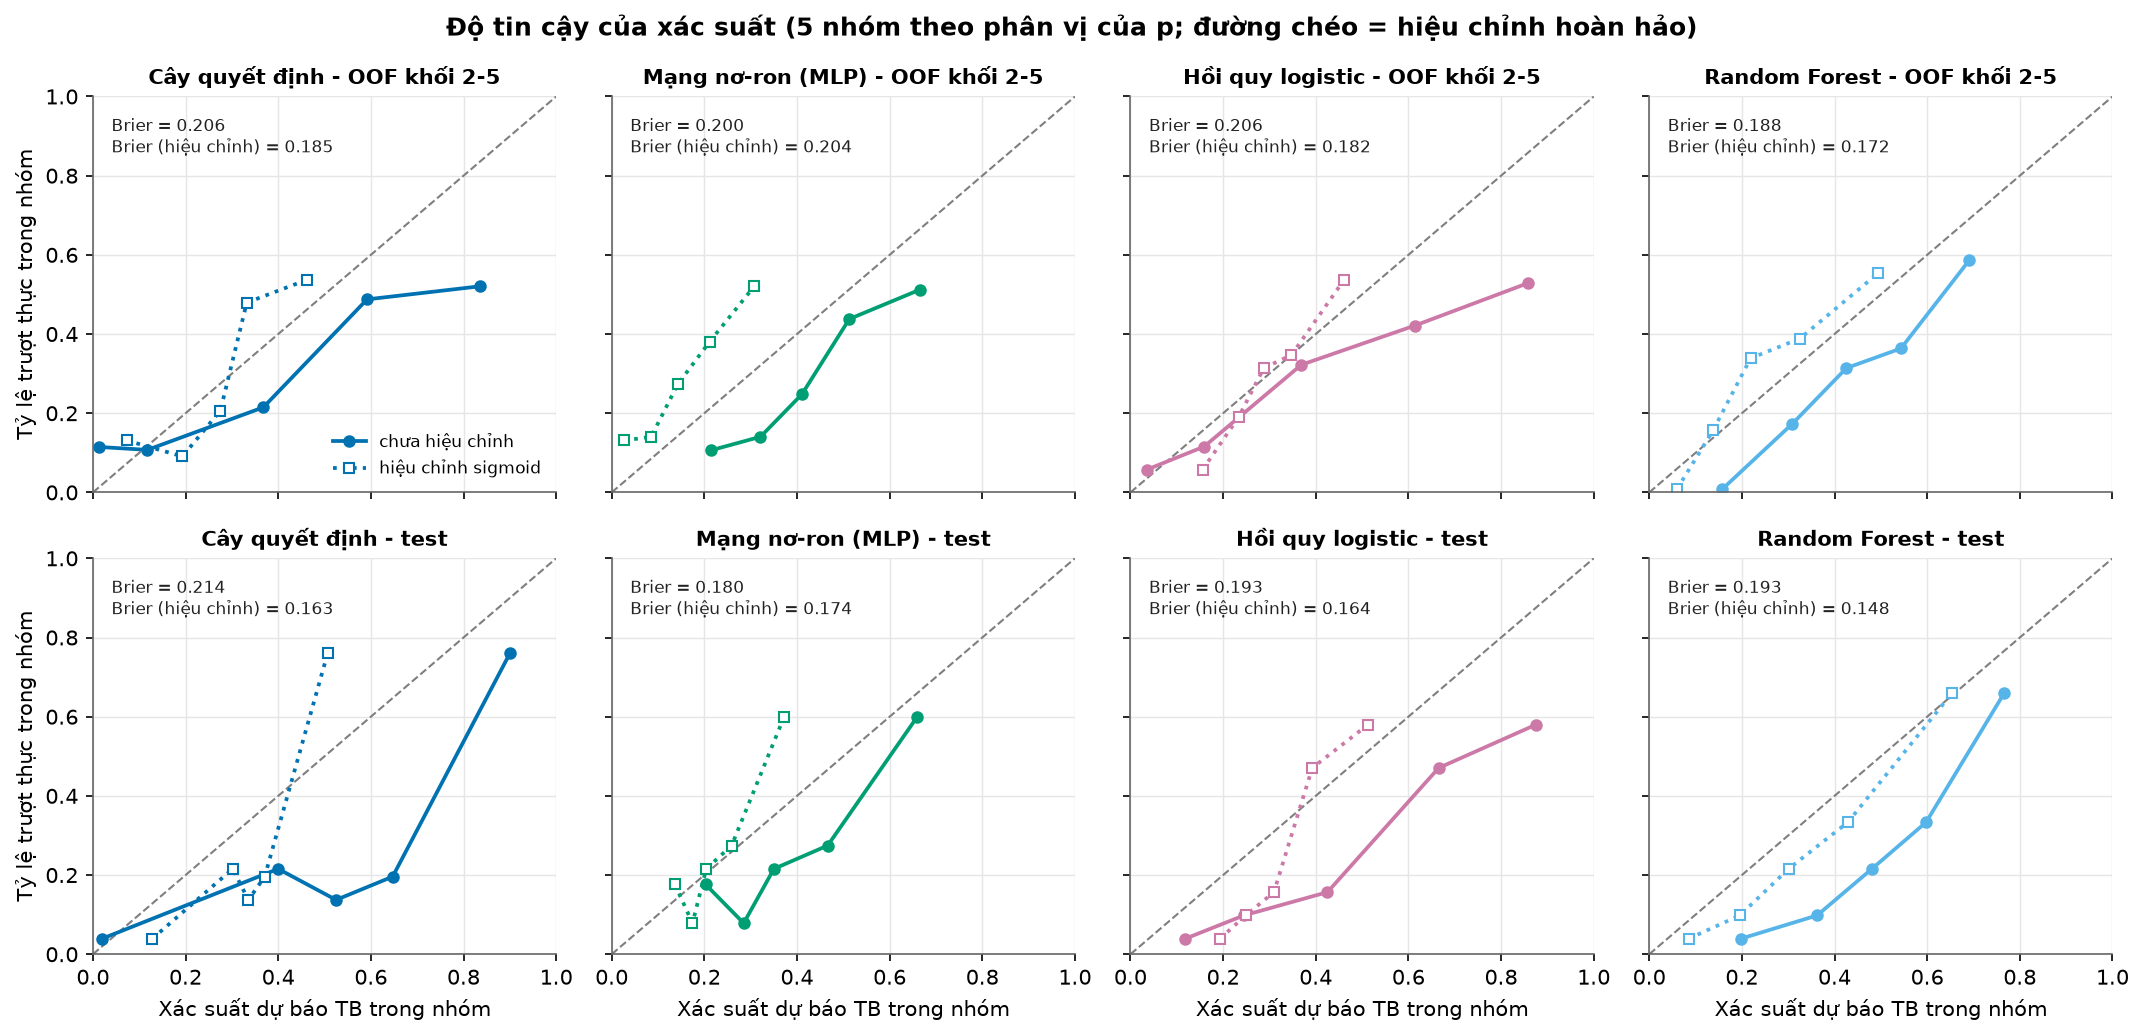

In [3]:
from IPython.display import Image
fig20 = ROOT / "outputs" / "figures" / "fig20_do_tin_cay_xac_suat.png"
display(Image(filename=str(fig20))) if fig20.exists() else print("Chưa có hình: chạy `python src/run_all.py` trước.")

**Nhận xét.**
- **Hàng trên (OOF khối 2–5):** các điểm chưa hiệu chỉnh (đường liền) của Random Forest nằm **dưới** đường chéo ở mọi nhóm: mô hình dự báo cao hơn thực tế. Sau hiệu chỉnh (đường chấm), các điểm sát đường chéo hơn.
- **Hàng dưới (test):** Brier của Random Forest giảm từ 0,193 xuống 0,148. Tuy vậy, trung bình xác suất đã hiệu chỉnh trên test (0,332) vẫn cao hơn tỷ lệ trượt của test (0,268). Một lý do: bộ hiệu chỉnh học từ điểm out-of-fold, còn mô hình dùng cho test được fit trên toàn bộ train và cho điểm thô cao hơn (trung bình 0,480 so với 0,425 ở OOF).
- Ở cây quyết định và Logistic, đường đã hiệu chỉnh trên test **dốc** hơn đường chéo: xác suất bị nén vào khoảng 0,1–0,5, nên các tổ rủi ro cao nhất bị đánh giá *thấp* hơn thực tế.
- Mỗi nhóm chỉ khoảng 50 dòng ở test, nên hình dạng chi tiết của đường rất nhiễu; chỉ nên đọc xu hướng chung.
- **Hệ quả:** con số "xác suất trượt" in cho quản đốc phải là bản đã hiệu chỉnh (phiếu cảnh báo ở mục 4 đã làm như vậy), và nên hiểu là ước lượng thô, sai lệch có thể vài điểm phần trăm.

## 2. Chính sách thiệt hại kỳ vọng
Phần so sánh các chính sách xếp hạng nằm ở `05_cost` (mục 2 và 3). Tóm tắt điều liên quan tới hiệu chỉnh:
- Ở lăng kính chính (b), xếp theo **điểm rủi ro** của Random Forest cho lợi ích ròng lớn nhất trên OOF, nên được chọn. Các bản thiệt hại kỳ vọng, kể cả bản dùng xác suất đã hiệu chỉnh, không tốt hơn. Các khoảng tin cậy chồng nhau nhiều, nên thực chất chưa phân biệt được ba cách xếp hạng.
- Ở lăng kính (a), kết quả ngược lại: xếp theo điểm rủi ro **thua** B1 có ý nghĩa thống kê, còn bản thiệt hại kỳ vọng có hiệu chỉnh lại **hơn** B1. Hiệu chỉnh chỉ có giá trị khi quy mô thiệt hại khác nhau nhiều giữa các tổ, như ở lăng kính (a).

## 3. Learning curve theo thời gian
**Cách làm.** Cố định khối validate cuối của train (khối 5), huấn luyện trên m ngày **ngay trước** khối đó (m = 5, 10, …), đo PR-AUC. Lặp lại với khối 4 để thấy độ dao động. Siêu tham số giữ cố định như đã chọn trên train (không dò lại theo m). Đường ngang là B1 (không cần học) và tỷ lệ trượt của khối (đoán bừa).

**Cách đọc.** Nếu đường còn đi lên khi m tăng thì thêm dữ liệu sẽ giúp; nếu đường phẳng hoặc dao động mạnh thì giới hạn nằm ở thông tin trong đặc trưng và ở nhiễu của khối validate nhỏ (140–148 dòng).

model                B1  Logistic  RandomForest
val_block m_days                               
4         5       0.465     0.569         0.470
          10      0.465     0.560         0.414
          15      0.465     0.516         0.472
          20      0.465     0.547         0.531
          25      0.465     0.546         0.548
          30      0.465     0.528         0.528
          32      0.465     0.531         0.545
5         5       0.527     0.464         0.633
          10      0.527     0.581         0.622
          15      0.527     0.555         0.599
          20      0.527     0.542         0.588
          25      0.527     0.587         0.678
          30      0.527     0.603         0.644
          35      0.527     0.590         0.647
          40      0.527     0.596         0.675

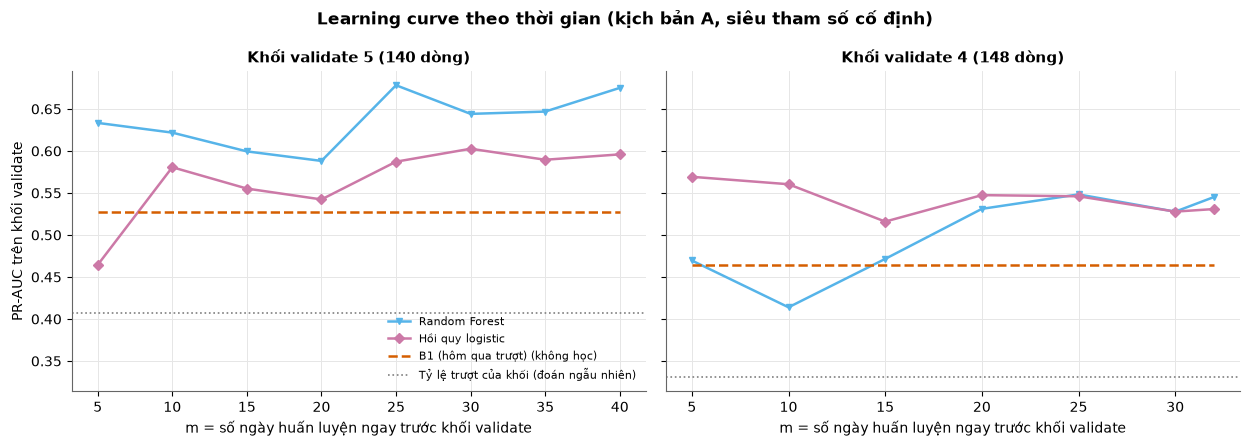

In [4]:
models = list(dict.fromkeys([main, "Logistic"]))
lc = LC.learning_curve(train, cv, sel["best"], "A", models, val_blocks=(5, 4))
display(lc.pivot_table(index=["val_block", "m_days"], columns="model", values="pr_auc").round(3))
fig = P.plot_learning_curve(lc, models); plt.show()

**Nhận xét.**
- **Khối 5:** Random Forest đạt 0,633 chỉ với 5 ngày huấn luyện, sau đó dao động trong khoảng 0,59–0,68 mà **không có xu hướng tăng rõ**. Logistic thì tăng từ 0,464 (5 ngày) lên khoảng 0,59–0,60 (từ 25 ngày).
- **Khối 4:** Random Forest **không hơn B1** (0,465) khi chỉ có 5–15 ngày (0,414–0,472), và chỉ vượt B1 từ khoảng 20 ngày trở lên (0,53–0,55). Logistic ổn định hơn ở khối này (0,52–0,57) và cao hơn Random Forest khi có ít ngày.
- Hai khối cho thứ tự khác nhau giữa Random Forest và Logistic: độ dao động giữa các khối validate lớn hơn tác động của việc thêm dữ liệu.
- **Kết luận:** với cùng các đặc trưng hiện có, thêm ngày dữ liệu của chính nhà máy này **chưa chắc** làm mô hình tốt hơn đáng kể. Giới hạn chủ yếu nằm ở lượng thông tin trong đặc trưng và ở nhiễu của khối validate nhỏ. Muốn cải thiện, nên thu thập **thêm loại thông tin** (ví dụ kế hoạch đơn hàng, thời điểm ghi nhận thưởng, lý do vắng mặt) hơn là chỉ thêm ngày.
- Thực tế triển khai: Random Forest cần khoảng **20 ngày lịch sử** trở lên mới ổn định hơn quy tắc B1.

## 4. Phiếu cảnh báo đầu ca
**Vì sao.** Đề yêu cầu chuyển kết quả thành khuyến nghị vận hành. Phiếu cảnh báo là dạng mà quản đốc dùng được ngay mỗi sáng: danh sách k tổ cần hỗ trợ, mức rủi ro, và 2–3 lý do chính.

**Cách làm.** `make_sheet` huấn luyện mô hình chính trên **mọi ngày trước D** (siêu tham số chọn trên train), chấm điểm các tổ của ngày D, xếp hạng theo điểm rủi ro (chính sách được chọn ở `05_cost`). Phiếu in hai con số:
- **Điểm rủi ro**: đầu ra thô của mô hình, chỉ dùng để xếp hạng;
- **Xác suất trượt ước tính**: điểm rủi ro sau hiệu chỉnh sigmoid (fit trên điểm out-of-fold của các ngày trước D), là con số quản đốc có thể đọc theo nghĩa đen.

Dòng lệnh tương đương: `python src/alert_sheet.py --date 2015-03-05 --k 3 --lens b`. Ô dưới in phiếu ngày 05/03 và tóm tắt ba ngày mẫu trong giai đoạn test.

In [5]:
rows = []
for d in ["2015-02-26", "2015-03-05", "2015-03-11"]:
    res = AS.make_sheet(df, d, 3, "b", pol, sel["best"][pol], ranking="p")
    s, full = res["sheet"], res["full"]
    if d == "2015-03-05":
        print(AS.to_markdown(res))
    rows.append({"ngay": d, "so_to_bo_phan": res["meta"]["n_today"], "so_to_truot_ca_ngay": int(full.actual_miss.sum()),
                 "canh_bao_dung_trong_3": int(s.actual_miss.sum()),
                 "diem_rui_ro_TB_3_to": s.risk_score.mean(), "xac_suat_hieu_chinh_TB_3_to": s.p_miss_cal.mean()})
pd.DataFrame(rows).round(2)

# Phiếu cảnh báo đầu ca - 2015-03-05 (Thursday)

- Mô hình: Random Forest (kịch bản A, siêu tham số chọn trên train), huấn luyện trên 53 ngày (1068 dòng) trước ngày này.
- Xếp hạng: top-k theo điểm rủi ro của mô hình (p chưa hiệu chỉnh); lăng kính (b) giao hàng (sản phẩm thiếu); k = 3 tổ trong tổng 19 tổ-bộ phận hôm nay.

| Hạng | Tổ | Bộ phận | Điểm rủi ro (dùng để xếp hạng) | Xác suất trượt ước tính (đã hiệu chỉnh) | Thiệt hại kỳ vọng (sản phẩm) | Lý do chính | Kết quả thực tế (chỉ để kiểm tra) |
|---|---|---|---|---|---|---|---|
| 1 | 9 | finishing | 0.76 | 65% | 642 | số công nhân = 8, trung vị train 34; SMV (thời gian chuẩn) = 2.9, trung vị train 15.3; chênh lệch TB 5 ngày trước = -0.171, trung vị train 0 | TRƯỢT (0.45 so với định mức 0.75) |
| 2 | 12 | finishing | 0.67 | 51% | 387 | số công nhân = 9, trung vị train 34; chênh lệch TB 5 ngày trước = -0.138, trung vị train 0; tỷ lệ trượt 5 ngày trước = 0.8, trung vị train 0.2 | đạt (0.87 so với định mức 0.80) |
| 3 | 2 | finishing |

,ngay,so_to_bo_phan,so_to_truot_ca_ngay,canh_bao_dung_trong_3,diem_rui_ro_TB_3_to,xac_suat_hieu_chinh_TB_3_to
0,2015-02-26,21,8,3,0.82,0.74
1,2015-03-05,19,3,1,0.69,0.55
2,2015-03-11,24,6,3,0.85,0.78


**Nhận xét.**
- Ở ba ngày mẫu (ngày đầu, giữa và cuối giai đoạn test, cố định trước trong `run_all.py`), phiếu cảnh báo đúng **3/3, 1/3 và 3/3** tổ, tổng cộng 7/9.
- Ngày 05/03 chỉ có 3/19 tổ-bộ phận trượt. Vì k cố định bằng 3 nên phiếu vẫn cảnh báo đủ 3 tổ, và 2 trong số đó đạt định mức. Cột xác suất đã hiệu chỉnh giúp quản đốc thấy mức độ: hôm đó tổ thứ 2 và 3 chỉ khoảng 50%, thấp hơn rõ so với các ngày khác (trung bình 3 tổ khoảng 74–78%).
- **Điểm rủi ro thô cao hơn xác suất hiệu chỉnh** khoảng 7–14 điểm phần trăm ở cả ba ngày (ví dụ 0,82 so với 0,74). Nếu chỉ in điểm thô với nhãn "xác suất", quản đốc sẽ đánh giá quá cao rủi ro; phiếu hiện in cả hai và ghi rõ con số nào dùng để đọc.
- **Đọc cột "Lý do chính" thận trọng:** các lý do như "số công nhân = 8" hay "SMV = 2,9" thực chất đang nói "đây là tổ finishing" (xem `06_interpret`, mục 2). Lý do hữu ích nhất cho quản đốc là các lý do về lịch sử gần đây (chênh lệch hoặc tỷ lệ trượt 5 ngày trước).
- Ba ngày mẫu không đủ để đánh giá hiệu quả; con số đánh giá đầy đủ trên 12 ngày test nằm ở `05_cost` (trung bình 2,08/3 tổ được cảnh báo đúng mỗi ngày).

## 5. Tổng kết

| Phân tích | Kết quả chính | Hệ quả |
|---|---|---|
| Độ tin cậy xác suất | Điểm thô cao hơn tỷ lệ thật 10–14 điểm phần trăm; hiệu chỉnh sigmoid sửa tốt cho Random Forest và Logistic, không dùng được cho MLP | Xếp hạng không đổi; mọi con số "xác suất" đưa cho người dùng phải là bản đã hiệu chỉnh |
| Learning curve | Không có xu hướng tăng rõ khi thêm ngày; Random Forest cần khoảng 20 ngày để ổn định hơn B1 | Cải thiện tiếp nên đến từ thông tin mới, không chỉ thêm dữ liệu cùng loại |
| Phiếu cảnh báo | 7/9 tổ được cảnh báo đúng ở ba ngày mẫu; phiếu in cả điểm rủi ro và xác suất đã hiệu chỉnh | Dùng được làm công cụ thí điểm; lý do về quy mô tổ thực chất là lý do "bộ phận" |